In [256]:
import os
import time
import glob
import platform
import random
import shutil
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import f1_score, classification_report, confusion_matrix


from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()


# 오류 발생시
# sklearn.set_config(display="text")

True

In [257]:
# from kaggle.api.kaggle_api_extended import KaggleApi

# api = KaggleApi()
# api.authenticate()

# output_dir = "/Users/kdt_0900_cjs/ml/resource/dataset"
# os.makedirs(output_dir, exist_ok=True)
# # https://www.kaggle.com/datasets/sanikamal/horses-or-humans-dataset
# api.dataset_download_files("drgfreeman/rockpaperscissors", path=output_dir, unzip=True)

# print("다운로드 완료")

In [258]:
base_path = "/Users/kdt_0900_cjs/ml/resource/dataset"
source = os.path.join(base_path, "rps-cv-images")

split_names = ("training", "validation", "test")
for split in split_names:
    os.makedirs(os.path.join(source, split), exist_ok=True)

classes = ("paper", "rock", "scissors")
for label in classes:
    if not os.path.isdir(os.path.join(source, label)):
        raise FileNotFoundError(f"클래스 폴더 없음: {os.path.join(source, label)}")
        
rng = random.Random(42)

for label in classes:
    images = sorted(glob.glob(os.path.join(source, label, "*.png")))
    rng.shuffle(images)      
    test_count = int(len(images)* 0.2)
    test_files = images[:test_count]
    rest = images[test_count:]

    train_count = int(len(rest)* 0.8)
    splits = {
        "training": rest[:train_count],
        "validation": rest[train_count:],
        "test": test_files,
    }

    for split, files in splits.items():
        target = os.path.join(source, split, label)
        os.makedirs(target, exist_ok=True)
        for file in files:
            shutil.copy2(file, os.path.join(target, os.path.basename(file)))  
        print(f"{split}/{label}: {len(files)}장")

training/paper: 456장
validation/paper: 114장
test/paper: 142장
training/rock: 464장
validation/rock: 117장
test/rock: 145장
training/scissors: 480장
validation/scissors: 120장
test/scissors: 150장


In [259]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(90),
    transforms.ToTensor(),
    transforms.ColorJitter(
        brightness=0.3,  
        contrast=0.3,    
        saturation=0.3, 
        hue=0.05  
    ),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])


target_transform = lambda y: torch.tensor([y], dtype=torch.float32)

In [260]:
train_path = os.path.join(base_path, "rps-cv-images", "training")
val_path = os.path.join(base_path, "rps-cv-images", "validation")
test_path = os.path.join(base_path, "rps-cv-images", "test")


train_dataset = ImageFolder(train_path, transform=train_transform)
val_dataset = ImageFolder(val_path, transform=test_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

In [261]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

In [262]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


In [263]:
model1 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

In [264]:
for param in model1.parameters():
    param.requires_grad= False

In [265]:
num_classes = len(train_dataset.classes)
model1 = nn.Sequential(
    model1.features,              
    nn.AdaptiveAvgPool2d((1, 1)), 
    nn.Flatten(),             
    nn.Dropout(0.2),
    nn.Linear(1280, num_classes), 
)

In [266]:
model1 = model1.to(device)

In [267]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()
    model[0].eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스의 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [268]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [269]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================={model_name} 학습 종료 ============================")
    return history

In [270]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1[-1].parameters(), lr=0.001)

In [271]:
history1 = train_model_multiclass(
    model=model1,
    model_name="Mobilenet-multiclass",
    train_loader=train_dataloader,
    val_loader = val_dataloader,
    criterion=criterion,
    optimizer = optimizer,
    epochs=30,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

=========================Mobilenet-multiclass 학습 시작 ============================
[Batch 20/44] Batch Loss: 0.6605, Batch Accuracy: 90.62%
[Batch 40/44] Batch Loss: 0.5213, Batch Accuracy: 84.38%
[Epoch: 1] | Train Loss: 0.7305 | Train Accuracy: 80.56%
[Epoch: 1] | Validation Loss: 0.6973 | Validation Accuracy: 84.64%
[Batch 20/44] Batch Loss: 0.5400, Batch Accuracy: 87.50%
[Batch 40/44] Batch Loss: 0.2977, Batch Accuracy: 96.88%
[Epoch: 2] | Train Loss: 0.3866 | Train Accuracy: 94.25%
[Epoch: 2] | Validation Loss: 0.5497 | Validation Accuracy: 89.19%
[Batch 20/44] Batch Loss: 0.2508, Batch Accuracy: 93.75%
[Batch 40/44] Batch Loss: 0.2241, Batch Accuracy: 96.88%
[Epoch: 3] | Train Loss: 0.2568 | Train Accuracy: 96.38%
[Epoch: 3] | Validation Loss: 0.4793 | Validation Accuracy: 89.76%
[Batch 20/44] Batch Loss: 0.2251, Batch Accuracy: 96.88%
[Batch 40/44] Batch Loss: 0.1553, Batch Accuracy: 100.00%
[Epoch: 4] | Train Loss: 0.2100 | Train Accuracy: 96.38%
[Epoch: 4] | Validation Loss: 0.4

In [272]:
from collections import Counter

for name, loader in [
    ("학습", train_dataloader),
    ("검증", val_dataloader),
    ("테스트", test_dataloader)
]:
    dataset = loader.dataset

    print(f"\n{name} 경로: {dataset.root}")
    print(f"이미지: {len(dataset)}장")
    print(f"배치: {len(loader)}개")
    print(f"배치 크기: {loader.batch_size}")
    print(f"drop_last: {loader.drop_last}")
    print("\n클래스 수:", num_classes, "| 라벨 매핑:", train_dataset.class_to_idx)
    
    counts = Counter(dataset.targets)
    for label, index in dataset.class_to_idx.items():
        print(f"  {label}: {counts[index]}장")


학습 경로: /Users/kdt_0900_cjs/ml/resource/dataset/rps-cv-images/training
이미지: 1400장
배치: 44개
배치 크기: 32
drop_last: False

클래스 수: 3 | 라벨 매핑: {'paper': 0, 'rock': 1, 'scissors': 2}
  paper: 456장
  rock: 464장
  scissors: 480장

검증 경로: /Users/kdt_0900_cjs/ml/resource/dataset/rps-cv-images/validation
이미지: 351장
배치: 11개
배치 크기: 32
drop_last: False

클래스 수: 3 | 라벨 매핑: {'paper': 0, 'rock': 1, 'scissors': 2}
  paper: 114장
  rock: 117장
  scissors: 120장

테스트 경로: /Users/kdt_0900_cjs/ml/resource/dataset/rps-cv-images/test
이미지: 437장
배치: 14개
배치 크기: 32
drop_last: False

클래스 수: 3 | 라벨 매핑: {'paper': 0, 'rock': 1, 'scissors': 2}
  paper: 142장
  rock: 145장
  scissors: 150장


In [273]:
best_model_path = os.path.join(base_path, "weights", "Mobilenet-multiclass", "best_model.pth")

In [274]:
model1.load_state_dict(torch.load(best_model_path))
model1 = model1.to(device)

In [275]:

model1.eval()
all_preds, all_labels, all_probs = [], [], []


test_loss, test_acc = evaluate_multiclass(
    model=model1,
    dataloader=test_dataloader,
    
    criterion = criterion,
    device = device
)

with torch.no_grad():
    for img, labels in test_dataloader:
        img = img.to(device)
        outputs = model1(img)
        preds = outputs.argmax(dim=1).cpu()
        probs = F.softmax(outputs, dim=1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.tolist())
        all_probs.extend(probs.tolist())


all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)   
class_names = train_dataset.classes

f1_macro = f1_score(all_labels, all_preds, average="macro")
f1_weighted = f1_score(all_labels, all_preds, average="weighted")

wrong_idx = np.where(all_preds != all_labels)[0]
for i in wrong_idx:
    path = test_dataset.samples[i][0]            
    print(os.path.basename(path),
          "정답:", class_names[all_labels[i]],
          "예측:", class_names[all_preds[i]],
          "예측 확률:", round(all_probs[i, all_preds[i]], 4))

print(f"Test F1 (macro):    {f1_macro:.4f}")
print(f"Test F1 (weighted): {f1_weighted:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

print(f"최종 모델의 평가")

print("Confusion Matrix (행=정답, 열=예측):")
print(confusion_matrix(all_labels, all_preds))
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}")

BqGdYFfhQ4sOU5Xl.png 정답: paper 예측: scissors 예측 확률: 0.4887
dZxpgHYRuQNv7T7A.png 정답: paper 예측: scissors 예측 확률: 0.6519
oWI7JL85eXDhRFcV.png 정답: paper 예측: scissors 예측 확률: 0.4754
6bGxG6c9DxmZBcIB.png 정답: rock 예측: scissors 예측 확률: 0.7853
BnnRzew7yA30gyts.png 정답: rock 예측: paper 예측 확률: 0.6367
FPa2M1e589cxIyfR.png 정답: rock 예측: paper 예측 확률: 0.5607
OavUnCwAEACzIK0A.png 정답: rock 예측: paper 예측 확률: 0.6024
UJ1D4UeUI0pnDG5h.png 정답: rock 예측: paper 예측 확률: 0.6016
XQVw2vKQl0dywWDc.png 정답: rock 예측: scissors 예측 확률: 0.5355
cy37is7PNfZQJ6SU.png 정답: rock 예측: paper 예측 확률: 0.461
yrzokMUYHlOLsRhQ.png 정답: rock 예측: paper 예측 확률: 0.4983
277q9TUTAsBAbTCj.png 정답: scissors 예측: paper 예측 확률: 0.4399
9YPMzKwEOWcIx1oN.png 정답: scissors 예측: paper 예측 확률: 0.8244
CTbANISUvZMD2T4L.png 정답: scissors 예측: paper 예측 확률: 0.7464
EkArrGlCdj8NNPbu.png 정답: scissors 예측: paper 예측 확률: 0.5197
KCh0XBlgDa526pBe.png 정답: scissors 예측: paper 예측 확률: 0.7467
Qonst5LFs961D77L.png 정답: scissors 예측: paper 예측 확률: 0.7023
Us8s37BoILcW4tgE.png 정답: scissors 예측: pap

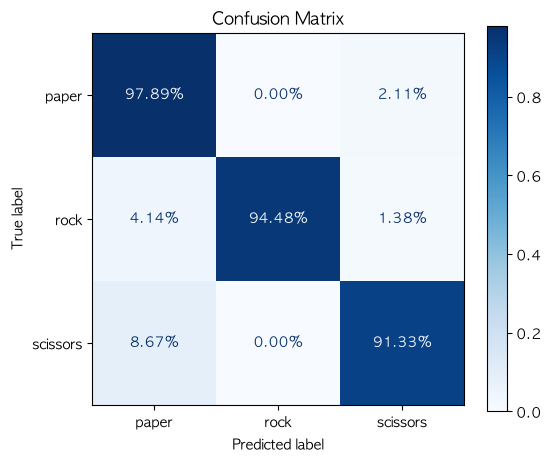

In [276]:
cm = confusion_matrix(all_labels, all_preds, normalize="true")  

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", values_format=".2%"
)
ax.set_title("Confusion Matrix")
plt.show()

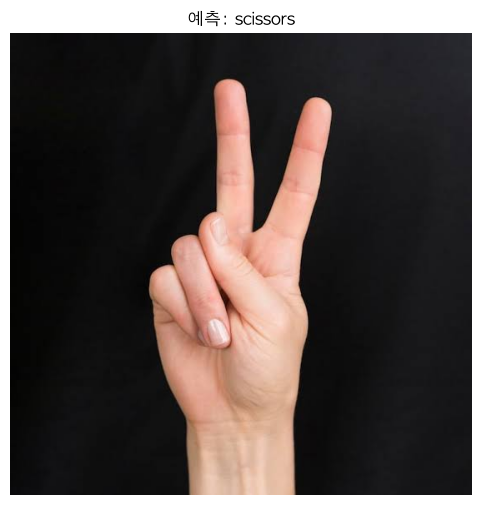

In [277]:
img_path = "/Users/kdt_0900_cjs/ml/resource/sissors.jpeg"
img = Image.open(img_path).convert("RGB")
img_tensor = test_transform(img)
img_batch = img_tensor.unsqueeze(0).to(device)

model1.eval()
with torch.no_grad():
    output = model1(img_batch)
    predicted_index = output.argmax(dim=1).item()
    predicted_class = train_dataset.classes[predicted_index]




korean_labels = {
    "paper": "보",
    "rock": "바위",
    "scissors": "가위",
}

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"예측: {predicted_class}")
plt.show()

이번 배치의 정답:
['paper', 'scissors', 'scissors', 'scissors', 'rock', 'scissors', 'scissors', 'paper', 'scissors', 'paper', 'scissors', 'scissors', 'rock', 'rock', 'paper', 'rock', 'paper', 'scissors', 'paper', 'rock', 'paper', 'paper', 'scissors', 'rock', 'scissors', 'paper', 'paper', 'scissors', 'paper', 'scissors', 'paper', 'scissors']
tensor([0, 2, 0, 0, 1, 2, 0, 0, 2, 0, 2, 2, 1, 1, 0, 1, 0, 2, 0, 1, 0, 0, 2, 1,
        2, 0, 0, 2, 0, 2, 0, 2])


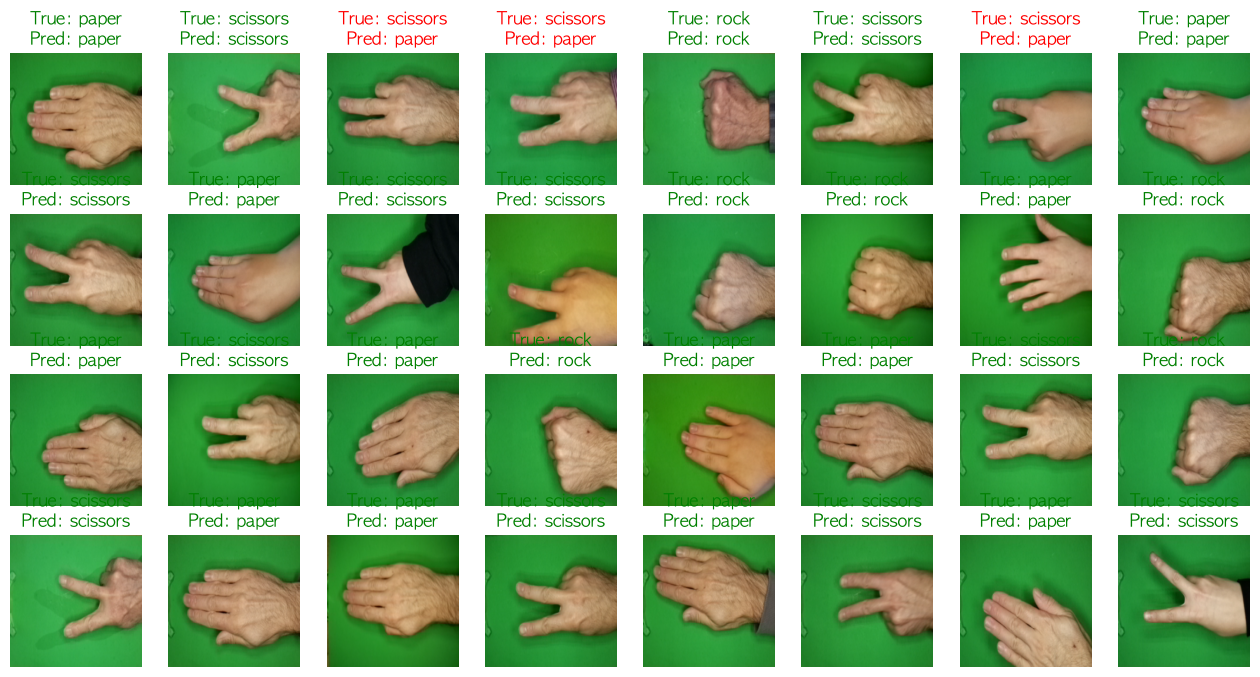

In [278]:
preview_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

imgs, labels = next(iter(preview_loader))

print("이번 배치의 정답:")
print([test_dataset.classes[index] for index in labels.tolist()])
class_to_idx = train_dataset.class_to_idx
class_dict = dict(enumerate(train_dataset.classes))
model1.eval()

imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model1(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()
    print(pred_labels)


fig, axes = plt.subplots(4, 8, figsize=(16, 8))

mean = np.array(mean)
std = np.array(std)

for ax , img, label, pred in zip(axes.flatten(), imgs, labels, pred_labels):
    img_np = img.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np * std + mean, 0, 1)
    true_label = int(label.item())
    pred_label = int(pred.item())
    color = "green" if true_label == pred_label else "red"
    ax.imshow(img_np)
    ax.set_title(f"True: {class_dict[true_label]}\nPred: {class_dict[pred_label]}", color=color)
    ax.axis("off")

plt.show()

In [279]:
def grad_cam(img, target_class=None):
    store = {}

    def forward(module, input, output):
        store["A"] = output.detach()
        output.register_hook(lambda grad : store.__setitem__("grad", grad.detach()))
        
    handle = model1[0].register_forward_hook(forward)

    try:
        model1.eval()
        x = img.unsqueeze(0).to(device)
        x.requires_grad_(True)
    
        logits = model1(x)
        if target_class is None:
            target_class = logits.argmax(dim=1).item()
        prob = F.softmax(logits, dim=1)[0, target_class].item()
    
        model1.zero_grad()
        logits[0, target_class].backward()
    
        alpha = store["grad"].mean(dim=(2, 3), keepdim=True)
        cam = F.relu((alpha * store["A"]).sum(dim =1, keepdim=True))
    
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners= False)
        cmap = cam[0, 0].cpu().numpy()
        cmap = (cmap - cmap.min()) / (cmap.max() - cmap.min() + 1e-8)
    finally:
        handle.remove()
        
    return cmap, target_class, prob

In [280]:
picked = []


for c in range(num_classes):
    idx = np.where((all_preds == all_labels) & (all_labels == c))[0]
    best = idx[np.argmax(all_probs[idx, c])]
    picked.append(("정분류", best))

wrong_sorted = wrong_idx[np.argsort(-all_probs[wrong_idx, all_preds[wrong_idx]])]
for i in wrong_sorted[:2]:
    picked.append(("오분류", i))

for kind, i in picked:
    print(f"[{kind}] {os.path.basename(test_dataset.samples[i][0])} | "
          f"정답: {class_names[all_labels[i]]} | 예측: {class_names[all_preds[i]]} "
          f"(p={all_probs[i, all_preds[i]]:.4f})")

[정분류] FxLuxwBp9Hw2th2O.png | 정답: paper | 예측: paper (p=0.9961)
[정분류] hi4vWQhDFKyTs4iJ.png | 정답: rock | 예측: rock (p=0.9986)
[정분류] fRkWkCO0r8ZJ6ury.png | 정답: scissors | 예측: scissors (p=0.9993)
[오분류] 9YPMzKwEOWcIx1oN.png | 정답: scissors | 예측: paper (p=0.8244)
[오분류] 6bGxG6c9DxmZBcIB.png | 정답: rock | 예측: scissors (p=0.7853)


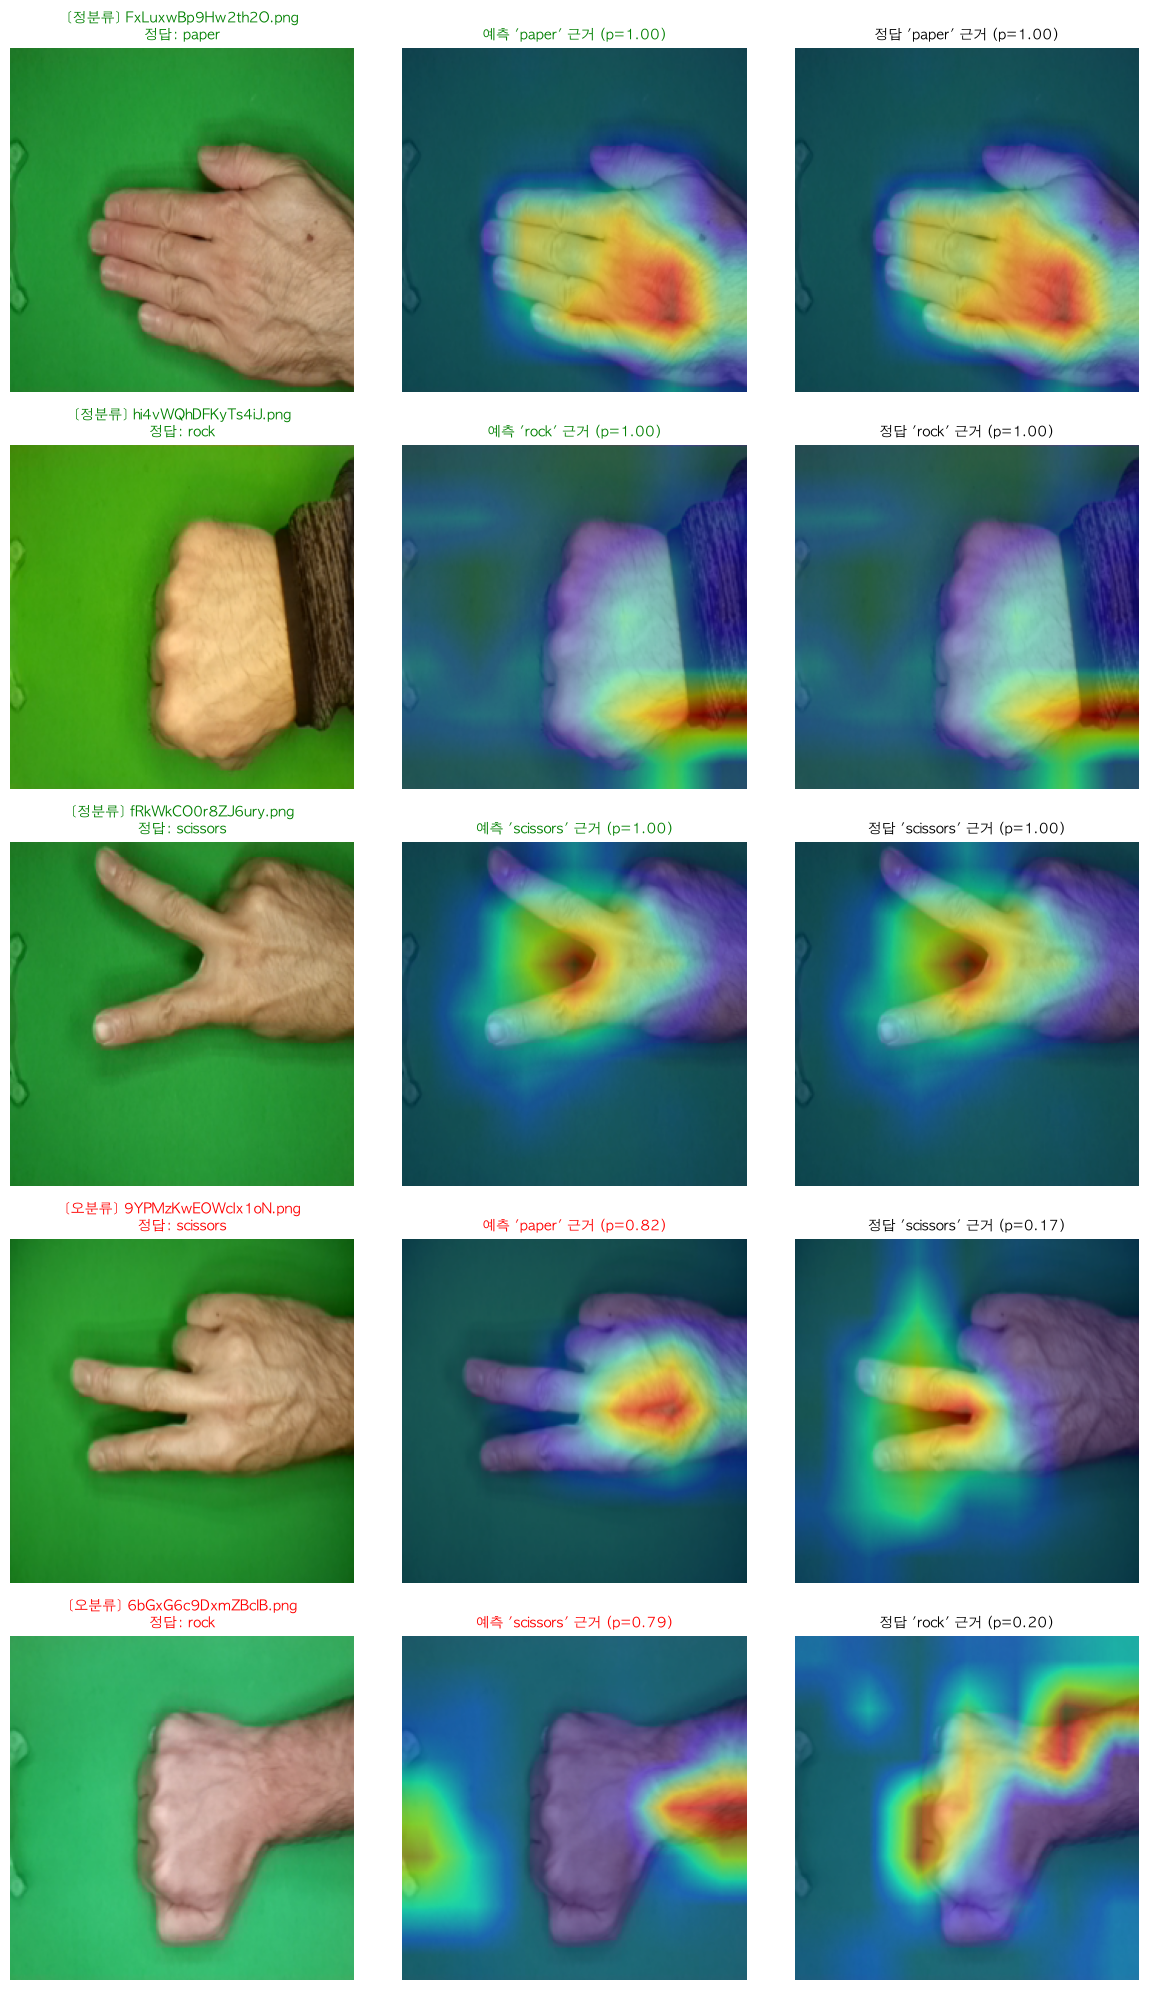

저장: /Users/kdt_0900_cjs/ml/resource/dataset/weights/Mobilenet-multiclass/gradcam.png


In [282]:
fig, axes = plt.subplots(len(picked), 3, figsize=(12, 4 * len(picked)))

for row, (kind, i) in enumerate(picked):
    img = test_dataset[i][0]
    y_true = int(all_labels[i])
    path = test_dataset.samples[i][0]
    color_origin = np.array(Image.open(path).convert("RGB").resize((224, 224))) / 255.0   

    cam_pred, c_pred, p_pred = grad_cam(img)                        
    cam_true, c_true, p_true = grad_cam(img, target_class=y_true)  

    color = "green" if kind == "정분류" else "red"

    axes[row, 0].imshow(color_origin)
    axes[row, 0].set_title(f"[{kind}] {os.path.basename(path)}\n정답: {class_names[y_true]}",
                           fontsize=10, color=color)

    axes[row, 1].imshow(color_origin)
    axes[row, 1].imshow(cam_pred, cmap="jet", alpha=0.45)
    axes[row, 1].set_title(f"예측 '{class_names[c_pred]}' 근거 (p={p_pred:.2f})", fontsize=10, color=color)

    axes[row, 2].imshow(color_origin)
    axes[row, 2].imshow(cam_true, cmap="jet", alpha=0.45)
    axes[row, 2].set_title(f"정답 '{class_names[c_true]}' 근거 (p={p_true:.2f})", fontsize=10)

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
save_path = os.path.join(base_path, "weights", "Mobilenet-multiclass", "gradcam.png")
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
print("저장:", save_path)